In [1]:
# Python libraries used in this notebook
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    roc_auc_score, roc_curve, brier_score_loss, log_loss,
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score
)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Comparative Statistical Modelling and Validation of Credit Default Risk

## Logistic Regression, Probit Regression and Decision Tree Comparison

**Final Exam Project**  
**Course:** Math Concepts for Developers  
**Author:** Karamfila Stoykova  
**Date:** 30 October 2026

## Abstract

This project investigates relationships between borrower characteristics and credit default using a reproducible synthetic sample. The analysis begins with descriptive statistics and comparison of defaulted and non-defaulted borrowers. It then estimates and validates four classification models: a single-factor logistic regression, a multivariable logistic regression, a probit regression and a shallow decision tree.

The models are evaluated on an independent test sample using ROC AUC, Brier score, log loss, confusion matrices, calibration by risk groups and the difference between training and test performance. Logistic-regression coefficients are interpreted through odds ratios, while variance inflation factors are used as a multicollinearity diagnostic.

The data are fully synthetic. The project demonstrates statistical modelling and validation methods and does not represent a production model or the portfolio of any institution.

## Table of Contents

1. Introduction  
2. Synthetic Sample Generation  
3. Exploratory Statistical Analysis  
4. Statistical Modelling Theory  
5. Model Development  
6. Model Validation and Comparison  
7. Results and Model Selection  
8. Limitations  
9. Conclusion  
10. References

## 1. Introduction

### 1.1 Problem Statement

Credit default is a binary outcome: a borrower either defaults or does not default within the defined observation period. The analytical task is to estimate how borrower characteristics are associated with this outcome and to determine whether a more complex model provides a meaningful improvement over a simple benchmark.

### 1.2 Objectives

- generate a reproducible synthetic borrower sample;
- describe the distributions of the explanatory variables;
- compare defaulted and non-defaulted borrowers;
- estimate logistic and probit regression models;
- compare statistical binary-response models with a nonlinear decision-tree benchmark;
- validate discrimination, calibration, probability accuracy and overfitting;
- interpret coefficients, odds ratios, limitations and model trade-offs.

### 1.3 Research Questions

1. Which borrower characteristics differ most clearly between defaulted and non-defaulted observations?
2. Does a multivariable logistic regression outperform a single-factor baseline?
3. Do logistic and probit links produce materially different predictions?
4. Does a shallow decision tree improve discrimination by capturing nonlinear rules?
5. Which model provides the best balance between predictive performance, calibration and interpretability?

### 1.4 Hypotheses

The full logistic regression is expected to outperform the DTI-only baseline because it includes several distinct dimensions of borrower risk. Probit regression is expected to perform similarly to logistic regression because the logistic and normal cumulative distribution functions have similar shapes. The decision tree may capture nonlinear relationships, but its probability estimates may be less stable or less well calibrated.

### 1.5 Alternative Modelling Approaches

Several mathematical approaches can be used to analyse a binary credit default outcome. The methods considered in this project differ in their mathematical assumptions, interpretation and ability to represent nonlinear relationships.

#### Logistic Regression

Logistic regression models the log-odds of default as a linear combination of the explanatory variables:

$$
\log\left(\frac{p_i}{1-p_i}\right)
=
\beta_0+\beta_1x_{1i}+\beta_2x_{2i}+\cdots+\beta_kx_{ki}
$$

where $p_i$ is the probability of default for borrower $i$.

An important advantage of logistic regression is its interpretability. Each estimated coefficient can be transformed into an odds ratio:

$$OR_j=e^{\beta_j}$$

The odds ratio describes how the odds of default change when the corresponding explanatory variable increases, while the remaining variables are held constant.

A limitation of logistic regression is that it assumes a linear relationship between the explanatory variables and the log-odds of default. Nonlinear effects and interactions must be introduced explicitly through additional terms.

#### Probit Regression

Probit regression addresses the same binary modelling problem but uses the cumulative distribution function of the standard normal distribution:

$$P(Y_i=1\mid X_i)=\Phi(X_i\boldsymbol{\beta})$$

The logistic and standard normal cumulative distribution functions have similar shapes. Therefore, logistic and probit regression often produce similar predicted probabilities and discriminatory performance.

Probit regression provides a useful robustness comparison because it uses a different link function. However, its coefficients do not provide the same direct odds-ratio interpretation as logistic-regression coefficients.

#### Decision Tree

A decision tree divides observations through a sequence of binary rules. An example of a possible rule is:

$$DTI_i>0.45$$

Decision trees can capture nonlinear relationships and interactions without requiring them to be specified in advance. However, decision trees can be sensitive to small changes in the training sample, may overfit and can produce less smooth probability estimates.

To reduce overfitting and preserve interpretability, the decision tree used in this project is restricted by:

- a maximum depth of 3;
- a minimum of 80 observations in each terminal leaf;
- a fixed random seed of 42.

#### More Complex Modelling Methods

More advanced methods such as random forests, gradient boosting and neural networks could also be applied. They are not included because the purpose of this project is to compare models whose mathematical structure, assumptions and validation results can be explained transparently.

The selected approaches provide a balanced comparison between a simple single-factor benchmark, an interpretable multivariable logistic model, an alternative statistical link function and a nonlinear decision-rule model.

## 2. Synthetic Sample Generation

### 2.1 Variables

| Variable | Description |
|---|---|
| `age` | Borrower age in years |
| `monthly_income` | Monthly disposable income |
| `loan_amount` | Outstanding loan amount |
| `dti` | Debt-to-income ratio |
| `credit_utilisation` | Utilised share of available revolving credit |
| `delinquencies_12m` | Number of recent delinquency events |
| `default_flag` | Binary outcome: 1 default, 0 non-default |

### 2.2 Data-Generating Process

The binary outcome is generated from a logistic probability:

$$p_i=P(Y_i=1\mid X_i)=\frac{1}{1+e^{-z_i}}$$

where the latent risk score contains linear effects, a DTI-utilisation interaction and a mild nonlinear loan-burden effect:

$$z_i=\beta_0+\beta_1DTI_i+\beta_2U_i+\beta_3L_i-\beta_4Income_i+\beta_5Age_i+\beta_6(DTI_iU_i)+\beta_7LoanBurden_i^2$$

The interaction makes the effect of DTI stronger at high utilisation. The nonlinear term gives the decision tree a realistic opportunity to detect structure not represented in the basic linear models.

In [2]:
RANDOM_SEED = 42
N = 5000
rng = np.random.default_rng(RANDOM_SEED)

age = np.clip(np.rint(rng.normal(42, 11, N)), 18, 75).astype(int)
monthly_income = np.clip(rng.lognormal(np.log(2600), 0.42, N), 800, 12000)
loan_amount = np.clip(rng.lognormal(np.log(18000), 0.65, N), 1000, 150000)
dti = rng.beta(2.4, 4.2, N)
credit_utilisation = rng.beta(2.0, 2.7, N)

delinquency_p = np.clip(0.03 + 0.16*dti + 0.14*credit_utilisation, 0, 0.50)
delinquencies_12m = rng.binomial(3, delinquency_p, N)

income_z = (np.log(monthly_income) - np.log(monthly_income).mean()) / np.log(monthly_income).std()
age_z = (age - age.mean()) / age.std()
loan_burden = loan_amount / (12 * monthly_income)

z = (
    -4.10 + 2.20*dti + 1.45*credit_utilisation
    + 0.70*delinquencies_12m - 0.35*income_z
    + 0.10*age_z + 1.35*(dti*credit_utilisation)
    + 0.18*np.minimum(loan_burden, 4)**2
)
true_pd = 1/(1+np.exp(-z))
default_flag = rng.binomial(1, true_pd, N)

data = pd.DataFrame({
    'age': age,
    'monthly_income': monthly_income,
    'loan_amount': loan_amount,
    'dti': dti,
    'credit_utilisation': credit_utilisation,
    'delinquencies_12m': delinquencies_12m,
    'default_flag': default_flag
})

print('Sample shape:', data.shape)
print(f'Default rate: {data.default_flag.mean():.2%}')
data.head()

Sample shape: (5000, 7)
Default rate: 15.82%


,age,monthly_income,loan_amount,dti,credit_utilisation,delinquencies_12m,default_flag
0,45,2333.038665,20185.243772,0.401193,0.276260,0,0
1,31,2292.693600,32291.434926,0.365250,0.278803,1,0
2,50,1940.439089,6912.945807,0.225580,0.419096,0,0
3,52,3112.649445,14953.239306,0.411355,0.351308,0,0
4,21,2869.284926,30855.696964,0.343195,0.320391,2,0


In [3]:
# Data-quality checks
checks = pd.Series({
    'No missing values': not data.isna().any().any(),
    'No duplicate rows': not data.duplicated().any(),
    'Age in expected range': data.age.between(18,75).all(),
    'Positive income': (data.monthly_income > 0).all(),
    'Positive loan amount': (data.loan_amount > 0).all(),
    'DTI in [0,1]': data.dti.between(0,1).all(),
    'Utilisation in [0,1]': data.credit_utilisation.between(0,1).all(),
    'Binary target': data.default_flag.isin([0,1]).all()
})
checks

No missing values        True
No duplicate rows        True
Age in expected range    True
Positive income          True
Positive loan amount     True
DTI in [0,1]             True
Utilisation in [0,1]     True
Binary target            True
dtype: bool

## 3. Exploratory Statistical Analysis

The exploratory analysis is deliberately focused on the modelling question. It describes the sample, compares defaulted and non-defaulted borrowers and checks linear relationships between candidate predictors.

In [4]:
features = ['age','monthly_income','loan_amount','dti','credit_utilisation','delinquencies_12m']
data[features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,5000.0,41.843,10.838,18.000,34.000,42.000,49.000,75.000
monthly_income,5000.0,2845.377,1265.061,800.000,1969.183,2578.191,3448.284,12000.000
loan_amount,5000.0,22150.130,16143.938,1438.066,11564.561,17628.257,27687.206,150000.000
dti,5000.0,0.362,0.176,0.009,0.225,0.346,0.486,0.920
credit_utilisation,5000.0,0.421,0.206,0.001,0.258,0.407,0.568,0.992
delinquencies_12m,5000.0,0.453,0.623,0.000,0.000,0.000,1.000,3.000


In [5]:
group_comparison = data.groupby('default_flag')[features].agg(['mean','median','std']).T
group_comparison.round(3)

default_flag                       0          1
age                mean       41.624     43.008
                   median     42.000     43.000
                   std        10.803     10.955
monthly_income     mean     2923.429   2430.053
                   median   2637.627   2250.605
                   std      1281.783   1081.839
loan_amount        mean    21424.179  26012.996
                   median  17303.859  19207.392
                   std     15208.626  19985.174
dti                mean        0.349      0.432
                   median      0.335      0.435
                   std         0.173      0.180
credit_utilisation mean        0.405      0.502
                   median      0.391      0.508
                   std         0.202      0.208
delinquencies_12m  mean        0.402      0.724
                   median      0.000      1.000
                   std         0.585      0.741

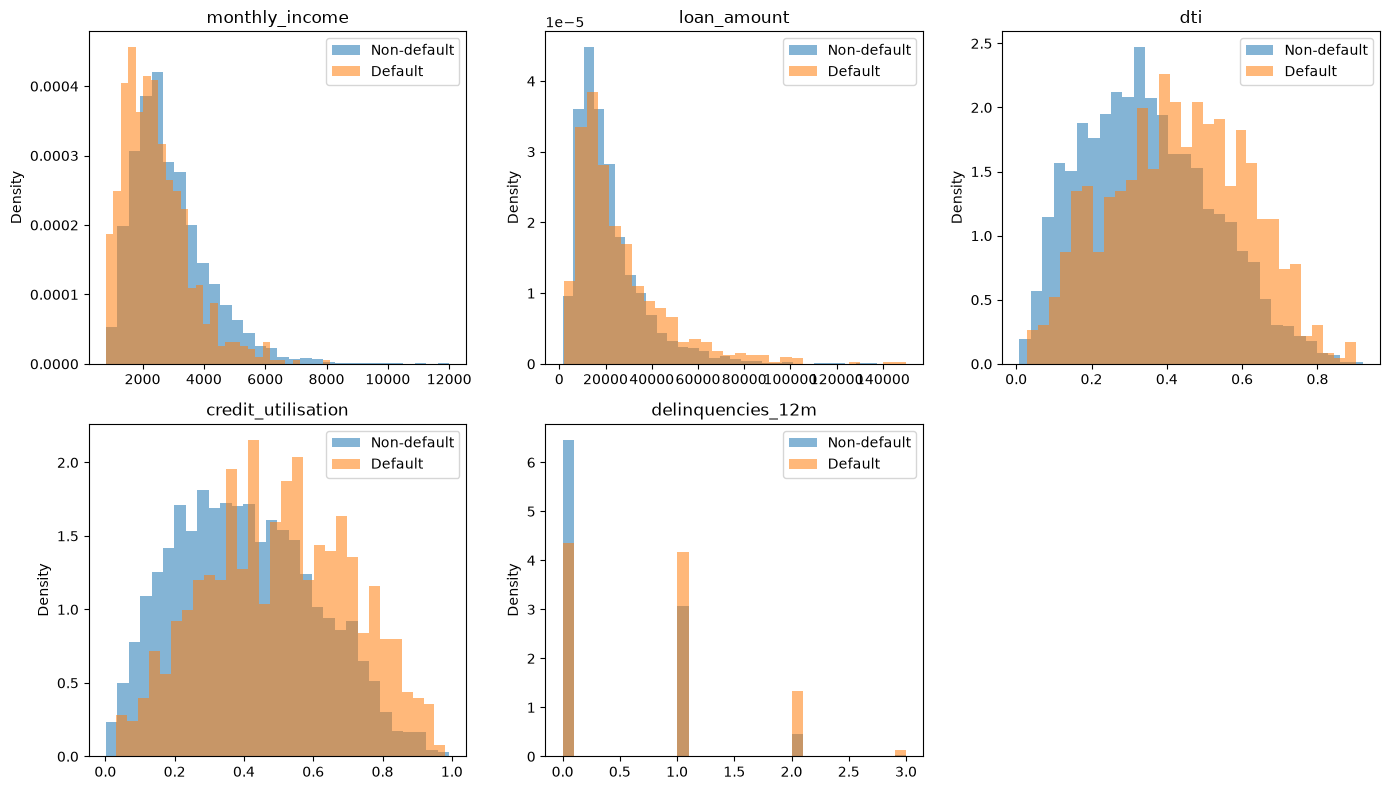

In [6]:
plot_vars = ['monthly_income','loan_amount','dti','credit_utilisation','delinquencies_12m']
fig, axes = plt.subplots(2,3,figsize=(14,8))
axes=axes.flatten()
for ax, var in zip(axes, plot_vars):
    ax.hist(data.loc[data.default_flag==0,var], bins=30, alpha=0.55, density=True, label='Non-default')
    ax.hist(data.loc[data.default_flag==1,var], bins=30, alpha=0.55, density=True, label='Default')
    ax.set_title(var)
    ax.set_ylabel('Density')
    ax.legend()
for ax in axes[len(plot_vars):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

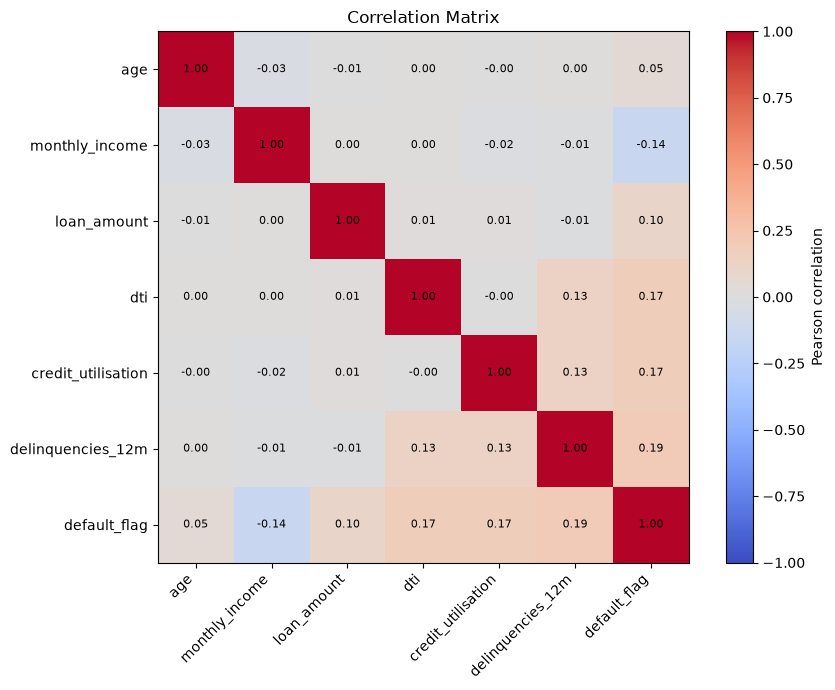

In [7]:
corr = data[features + ['default_flag']].corr()
fig, ax = plt.subplots(figsize=(9,7))
im=ax.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns,rotation=45,ha='right'); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
plt.colorbar(im,ax=ax,label='Pearson correlation')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

## 4. Statistical Modelling Theory

### 4.1 Logistic Regression

Logistic regression models the log-odds of default:

$$\log\left(\frac{p_i}{1-p_i}\right)=\beta_0+\beta_1x_{1i}+\cdots+\beta_kx_{ki}$$

The odds ratio associated with a one-unit increase in $x_j$ is:

$$OR_j=e^{\beta_j}$$

### 4.2 Probit Regression

Probit regression uses the cumulative standard normal distribution:

$$P(Y_i=1\mid X_i)=\Phi(X_i\beta)$$

### 4.3 Decision Tree

A decision tree partitions the feature space through sequential rules. A shallow tree can detect nonlinearities and interactions while remaining understandable.

### 4.4 Validation Measures

Discrimination is evaluated with ROC AUC. Probability accuracy is evaluated with Brier score and log loss:

$$Brier=\frac{1}{n}\sum_{i=1}^n(p_i-y_i)^2$$

$$LogLoss=-\frac{1}{n}\sum_{i=1}^n[y_i\log(p_i)+(1-y_i)\log(1-p_i)]$$

## 5. Model Development

The sample is divided into 70% training and 30% test observations using stratification. All model comparison is based on the untouched test sample.

In [8]:
X = data[features].copy()
y = data['default_flag'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
)
print('Training observations:', len(X_train), f'| default rate {y_train.mean():.2%}')
print('Test observations:', len(X_test), f'| default rate {y_test.mean():.2%}')

Training observations: 3500 | default rate 15.83%
Test observations: 1500 | default rate 15.80%


In [9]:
baseline_logit = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=1e6, max_iter=2000, random_state=RANDOM_SEED))
])
baseline_logit.fit(X_train[['dti']], y_train)

full_logit = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=1e6, max_iter=2000, random_state=RANDOM_SEED))
])
full_logit.fit(X_train, y_train)

scaler_probit = StandardScaler()
X_train_s = pd.DataFrame(scaler_probit.fit_transform(X_train), columns=features, index=X_train.index)
X_test_s = pd.DataFrame(scaler_probit.transform(X_test), columns=features, index=X_test.index)
probit = sm.Probit(y_train, sm.add_constant(X_train_s)).fit(disp=False)

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=80, random_state=RANDOM_SEED)
tree.fit(X_train, y_train)

print('Models fitted successfully.')

Models fitted successfully.


### 5.1 Logistic Coefficients and Odds Ratios

The coefficient table uses standardised predictors, so each coefficient represents an increase of one training-sample standard deviation.

In [10]:
coef = full_logit.named_steps['model'].coef_[0]
coefficient_table = pd.DataFrame({
    'Variable': features,
    'Standardised coefficient': coef,
    'Odds ratio per 1 SD': np.exp(coef)
}).sort_values('Standardised coefficient', key=np.abs, ascending=False)
coefficient_table.round(4)

,Variable,Standardised coefficient,Odds ratio per 1 SD
1,monthly_income,-0.5404,0.5825
4,credit_utilisation,0.4605,1.5848
5,delinquencies_12m,0.4528,1.5728
3,dti,0.4224,1.5256
2,loan_amount,0.2704,1.3105
0,age,0.1305,1.1394


In [11]:
vif_table = pd.DataFrame({
    'Variable': features,
    'VIF': [variance_inflation_factor(X_train_s.values, i) for i in range(len(features))]
})
vif_table.round(3)

,Variable,VIF
0,age,1.003
1,monthly_income,1.004
2,loan_amount,1.001
3,dti,1.017
4,credit_utilisation,1.021
5,delinquencies_12m,1.037


## 6. Model Validation and Comparison

Validation covers independent test performance, discrimination, probability accuracy, classification performance, calibration, overfitting and multicollinearity.

In [12]:
models = {
    'Baseline Logit': {
        'train': baseline_logit.predict_proba(X_train[['dti']])[:,1],
        'test': baseline_logit.predict_proba(X_test[['dti']])[:,1]
    },
    'Full Logit': {
        'train': full_logit.predict_proba(X_train)[:,1],
        'test': full_logit.predict_proba(X_test)[:,1]
    },
    'Probit': {
        'train': np.asarray(probit.predict(sm.add_constant(X_train_s))),
        'test': np.asarray(probit.predict(sm.add_constant(X_test_s)))
    },
    'Decision Tree': {
        'train': tree.predict_proba(X_train)[:,1],
        'test': tree.predict_proba(X_test)[:,1]
    }
}

rows=[]
threshold=0.30
for name,p in models.items():
    pred=(p['test']>=threshold).astype(int)
    rows.append({
        'Model':name,
        'Train AUC':roc_auc_score(y_train,p['train']),
        'Test AUC':roc_auc_score(y_test,p['test']),
        'AUC gap':roc_auc_score(y_train,p['train'])-roc_auc_score(y_test,p['test']),
        'Brier score':brier_score_loss(y_test,p['test']),
        'Log loss':log_loss(y_test,p['test']),
        'Accuracy':accuracy_score(y_test,pred),
        'Precision':precision_score(y_test,pred,zero_division=0),
        'Recall':recall_score(y_test,pred,zero_division=0),
        'F1':f1_score(y_test,pred,zero_division=0)
    })
results=pd.DataFrame(rows).set_index('Model').sort_values('Test AUC',ascending=False)
results.round(4)

,Train AUC,Test AUC,AUC gap,Brier score,Log loss,Accuracy,Precision,Recall,F1
Model,,,,,,,,,
Full Logit,0.7545,0.7495,0.0050,0.1169,0.3801,0.8247,0.4278,0.3249,0.3693
Probit,0.7543,0.7489,0.0054,0.1170,0.3802,0.8247,0.4270,0.3207,0.3663
Baseline Logit,0.6204,0.6666,-0.0462,0.1278,0.4163,0.8293,0.2286,0.0338,0.0588
Decision Tree,0.6989,0.6625,0.0364,0.1269,0.4128,0.8000,0.3368,0.2743,0.3023


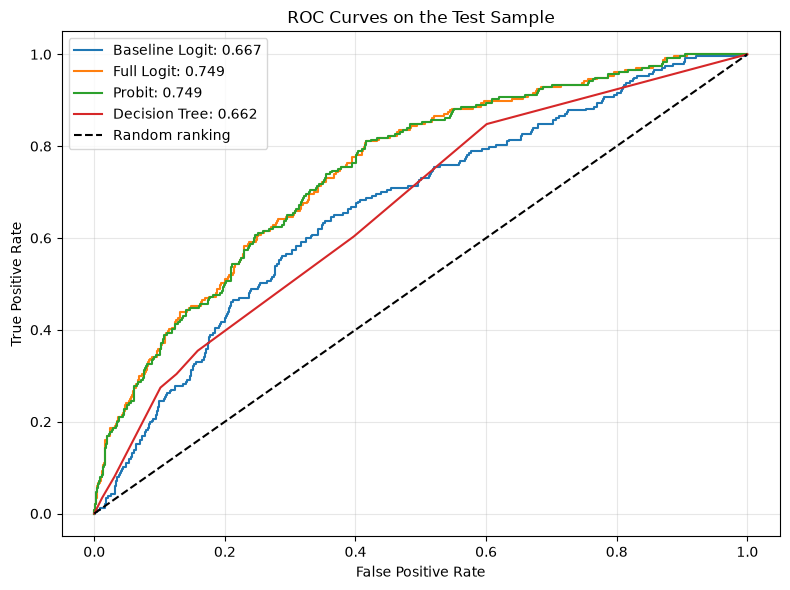

In [13]:
plt.figure(figsize=(8,6))
for name,p in models.items():
    fpr,tpr,_=roc_curve(y_test,p['test'])
    auc=roc_auc_score(y_test,p['test'])
    plt.plot(fpr,tpr,label=f'{name}: {auc:.3f}')
plt.plot([0,1],[0,1],'k--',label='Random ranking')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves on the Test Sample')
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

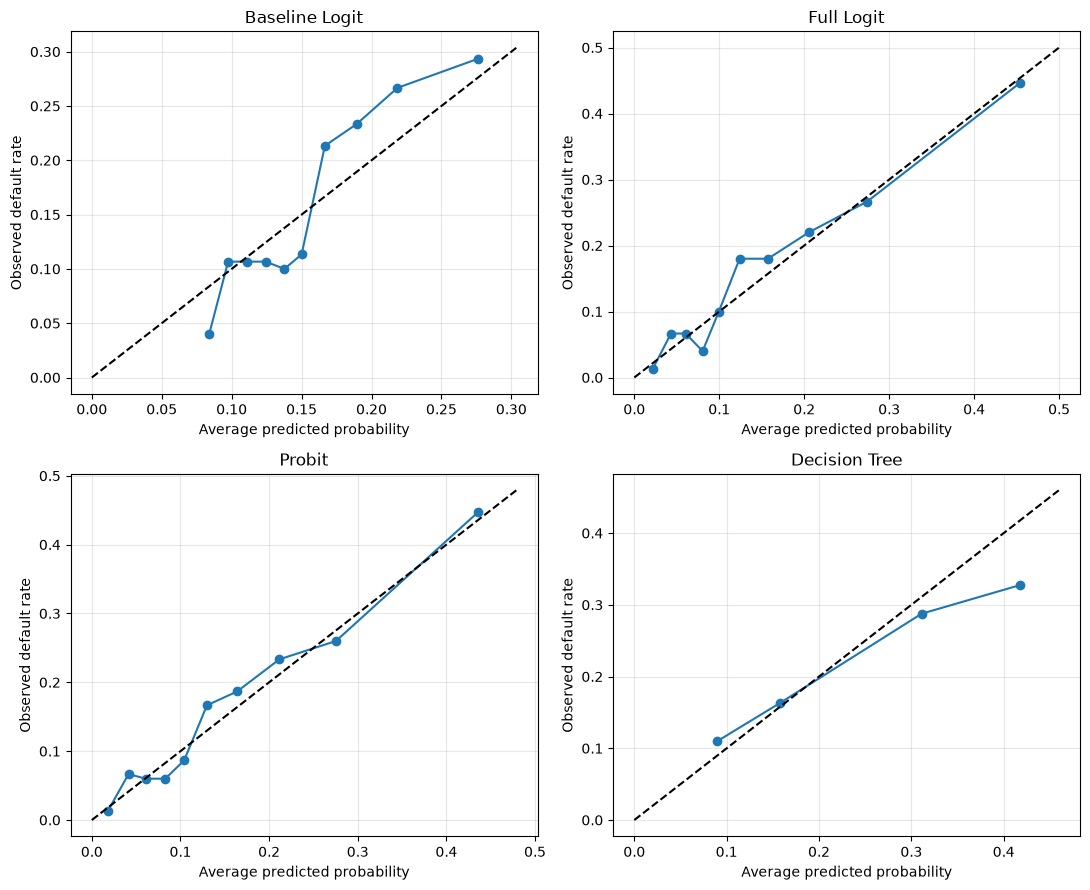

In [14]:
def calibration_table(probabilities, observed, groups=10):
    frame=pd.DataFrame({'predicted':probabilities,'observed':np.asarray(observed)})
    frame['group']=pd.qcut(frame['predicted'],q=groups,duplicates='drop')
    return frame.groupby('group',observed=False).agg(
        borrowers=('observed','size'),
        average_predicted=('predicted','mean'),
        observed_rate=('observed','mean')
    ).reset_index(drop=True)

calibration_tables={name:calibration_table(p['test'],y_test) for name,p in models.items()}

fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,(name,tab) in zip(axes.flatten(),calibration_tables.items()):
    ax.plot(tab.average_predicted,tab.observed_rate,'o-',label=name)
    ax.plot([0,tab.average_predicted.max()*1.1],[0,tab.average_predicted.max()*1.1],'k--')
    ax.set_title(name)
    ax.set_xlabel('Average predicted probability')
    ax.set_ylabel('Observed default rate')
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

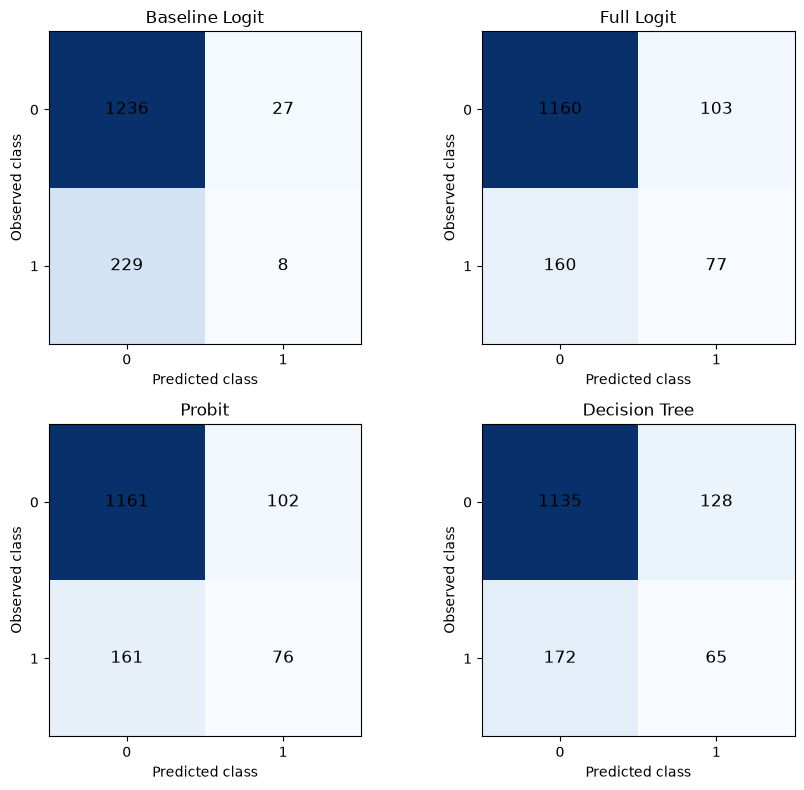

In [15]:
fig,axes=plt.subplots(2,2,figsize=(9,8))
for ax,(name,p) in zip(axes.flatten(),models.items()):
    cm=confusion_matrix(y_test,(p['test']>=0.30).astype(int))
    ax.imshow(cm,cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j,i,cm[i,j],ha='center',va='center',fontsize=12)
    ax.set_title(name)
    ax.set_xticks([0,1])
    ax.set_yticks([0,1])
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Observed class')
plt.tight_layout()
plt.show()

In [16]:
thresholds=[0.20,0.30,0.40,0.50]
p=models['Full Logit']['test']
threshold_rows=[]
for t in thresholds:
    pred=(p>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_test,pred).ravel()
    threshold_rows.append({
        'Threshold':t,
        'Accuracy':accuracy_score(y_test,pred),
        'Precision':precision_score(y_test,pred,zero_division=0),
        'Recall':recall_score(y_test,pred,zero_division=0),
        'Specificity':tn/(tn+fp),
        'F1':f1_score(y_test,pred,zero_division=0)
    })
pd.DataFrame(threshold_rows).round(4)

,Threshold,Accuracy,Precision,Recall,Specificity,F1
0,0.2,0.7460,0.3154,0.5190,0.7886,0.3923
1,0.3,0.8247,0.4278,0.3249,0.9184,0.3693
2,0.4,0.8440,0.5161,0.2025,0.9644,0.2909
3,0.5,0.8460,0.5682,0.1055,0.9850,0.1779


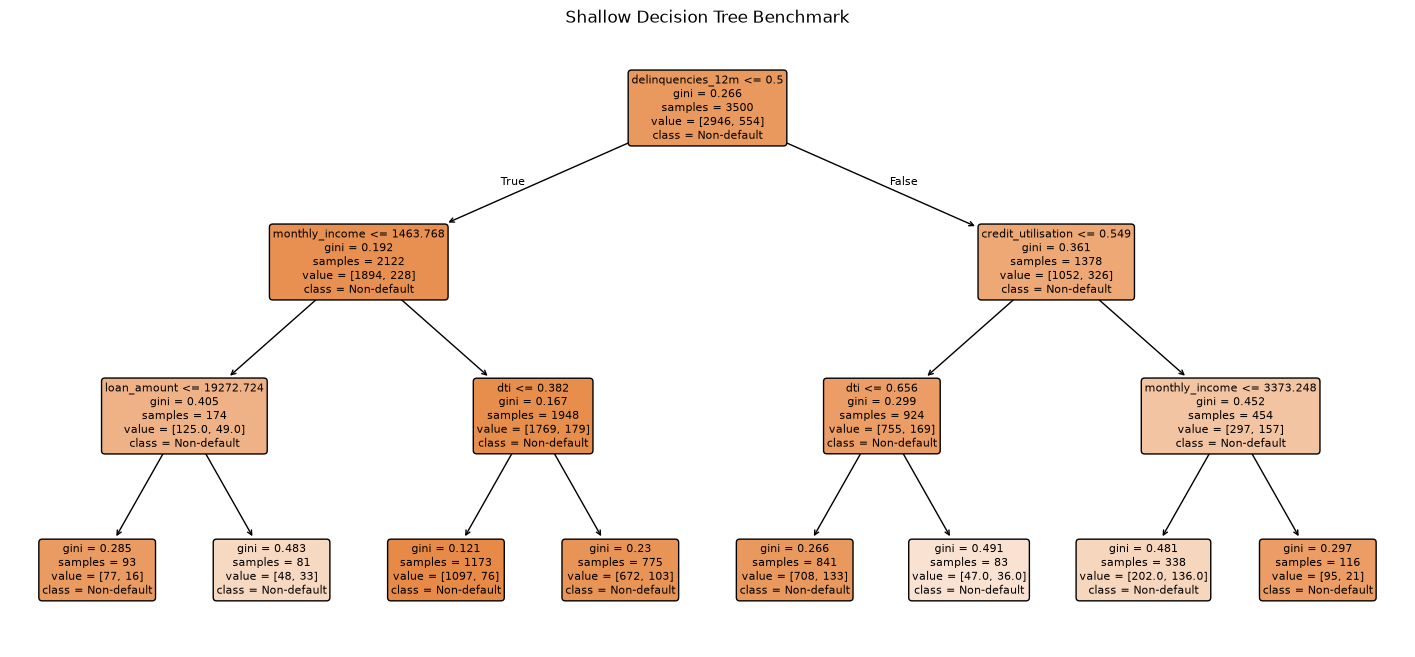

In [17]:
plt.figure(figsize=(18,8))
plot_tree(tree,feature_names=features,class_names=['Non-default','Default'],filled=True,rounded=True,fontsize=8)
plt.title('Shallow Decision Tree Benchmark')
plt.show()

## 7. Results and Model Selection

The final model decision should not be based on one statistic. The preferred model should combine acceptable test-sample discrimination, low Brier score and log loss, reasonable calibration, a small train-test AUC gap and clear interpretation.

The DTI-only model provides a transparent benchmark but omits important risk information. The full logistic model incorporates several borrower characteristics and supports odds-ratio interpretation. Probit provides a robustness check for the link-function assumption. The shallow decision tree tests whether simple nonlinear partitions materially improve performance.

The final interpretation will be completed using the model-comparison table and validation plots after all cells are run.

## 8. Limitations

1. The sample is synthetic and embeds assumed relationships.
2. The outcome is generated from a known mathematical process, so results cannot be generalised to real borrowers.
3. The candidate variables exclude macroeconomic, behavioural time-series and product information.
4. A single train-test split introduces sampling variability.
5. Calibration is assessed descriptively by groups rather than through a complete validation framework.
6. Threshold selection does not incorporate the economic cost of false positives and false negatives.
7. The project does not address reject inference, sample selection, missing-data mechanisms or temporal drift.

## 9. Conclusion

This project follows one coherent analytical path: generate a borrower sample, explore relationships, estimate competing models and validate them on independent observations.

The comparison demonstrates why a single accuracy measure is insufficient. ROC AUC evaluates ranking, Brier score and log loss evaluate probability accuracy, calibration groups compare predicted and observed risk, and the train-test gap provides an overfitting diagnostic.

The conclusions apply only to the synthetic sample. The value of the project lies in the modelling and validation process rather than in the numerical results themselves.

## 10. References

1. Course lecture: *Statistics*.
2. Course lecture: *Linear Algebra*.
3. Course lecture: *Calculus*.
4. Course document: *Final Exam Project Guidelines*.
5. scikit-learn documentation: LogisticRegression, DecisionTreeClassifier and model evaluation metrics.
6. statsmodels documentation: Probit and variance inflation factor.
7. NumPy, pandas and Matplotlib documentation.